In [1]:
modules = ["pandas","missingno", "seaborn", "matplotlib"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho!")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
missingno  encontrado
seaborn  encontrado
matplotlib  encontrado
¡Terminado!


In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
path = r'../../data/limpio_merged_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,mDvolatilidad_50_mDbinance,mDvolatilidad_200_mDbinance,mDrango_dia_mDbinance,mDmomentum_50_mDbinance,mDmomentum_200_mDbinance,mDSMA_50_mDbinance,mDSMA_200_mDbinance,mDEMA_50_mDbinance,mDEMA_200_mDbinance,mD_RSI_mDbinance
0,2022-03-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,606.7,NaN,NaN,NaN,NaN,39127.700000,39127.700000,NaN
1,2022-03-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,827.5,NaN,NaN,NaN,NaN,39137.401961,39130.161692,NaN
2,2022-03-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,345.1,NaN,NaN,NaN,NaN,39108.527374,39122.907346,NaN
3,2022-03-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,829.8,NaN,NaN,NaN,NaN,39063.636105,39111.373940,NaN
4,2022-03-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,856.9,NaN,NaN,NaN,NaN,39049.764100,39107.379174,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1093,2025-03-01,84349.95,86558.00,83824.78,86064.53,25785.05464,3700728.0,2.219179e+09,97742.7420,82128.37695,...,5367.658728,17393.209564,2228.7,-8667.8,25457.2,97698.522,82109.0375,95256.733272,85612.086844,23.649004
1094,2025-03-02,86064.54,95000.00,85050.60,94270.00,54889.09045,7403218.0,5.174395e+09,97736.1422,82306.31000,...,5628.295132,17314.542268,340.2,-9191.0,26723.4,97514.702,82242.6545,94869.077066,85609.692945,24.587165
1095,2025-03-03,94269.99,94416.46,85117.11,86220.61,59171.10218,9797860.0,5.101769e+09,97569.6532,82449.70775,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1096,2025-03-04,86221.16,86807.98,82464.84,83756.58,20827.67236,4065252.0,1.744455e+09,97354.0628,82574.11765,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Descripción general

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1098 entries, 0 to 1097
Data columns (total 43 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   timestamp                    1098 non-null   object 
 1   open_binance                 1001 non-null   float64
 2   high_binance                 1001 non-null   float64
 3   low_binance                  1001 non-null   float64
 4   close_binance                1001 non-null   float64
 5   volume_binance               1001 non-null   float64
 6   trades_binance               1001 non-null   float64
 7   volumen_binance              1001 non-null   float64
 8   SMA_50_binance               952 non-null    float64
 9   SMA_200_binance              802 non-null    float64
 10  EMA_50_binance               1001 non-null   float64
 11  EMA_200_binance              1001 non-null   float64
 12  var_diaria_binance           1000 non-null   float64
 13  volatilidad_50_bin

In [12]:
df.describe()

,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,EMA_50_binance,...,mDvolatilidad_50_mDbinance,mDvolatilidad_200_mDbinance,mDrango_dia_mDbinance,mDmomentum_50_mDbinance,mDmomentum_200_mDbinance,mDSMA_50_mDbinance,mDSMA_200_mDbinance,mDEMA_50_mDbinance,mDEMA_200_mDbinance,mD_RSI_mDbinance
count,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1.001000e+03,1.001000e+03,952.000000,802.000000,1001.000000,...,1046.000000,896.000000,1095.000000,1045.000000,895.000000,1046.000000,896.000000,1095.000000,1095.000000,1082.000000
mean,44885.383646,45783.803297,43982.254555,44936.418172,96546.930287,3.253934e+06,2.839404e+09,44265.171370,42156.840590,43371.964633,...,3157.089053,6813.754616,952.056164,2657.907560,11822.615196,43018.992891,40076.571388,42905.100970,39928.576258,52.673227
std,25525.994779,26054.543940,24954.674622,25547.436209,117452.960263,2.751000e+06,2.413818e+09,24376.320886,19491.028807,23902.137409,...,2372.176174,4504.960882,1101.763050,9901.652611,17084.402517,23414.429712,19128.498126,22695.886804,17639.004024,17.833387
min,15781.290000,16315.000000,15476.000000,15781.290000,7047.904300,3.108520e+05,2.508957e+08,16782.697600,19514.264250,17109.561575,...,337.468777,1590.916843,8.600000,-19612.500000,-28358.100000,16775.238000,19505.066500,17102.789867,20704.501961,6.247350
25%,23554.850000,24226.000000,23111.040000,23554.850000,25674.006220,1.174697e+06,1.186444e+09,23650.553650,25536.762125,23250.966341,...,1554.856222,3269.203933,277.350000,-3006.400000,1643.300000,24328.787500,23896.323750,25324.769710,26027.254632,40.838976
50%,31156.200000,31804.200000,30570.270000,31454.230000,42203.198712,2.037025e+06,2.028031e+09,31471.977600,33887.138625,29360.864935,...,2906.146547,4736.220650,567.500000,1273.500000,10213.300000,31928.267000,30282.954000,34187.916861,33698.505674,51.810964
75%,63990.020000,65419.000000,62700.000000,64012.000000,121888.571910,4.852404e+06,3.726653e+09,63672.817200,62572.265488,63098.264789,...,3866.962733,9908.973733,1216.300000,6546.400000,24272.250000,62072.512000,60038.403250,62156.629538,55714.159166,64.446309
max,106143.820000,109588.000000,105321.490000,106143.820000,760705.362783,1.522359e+07,1.725352e+10,99340.804800,82574.117650,98904.250959,...,12669.265592,18007.961673,10163.400000,38194.200000,49509.600000,99302.210000,82242.654500,98872.302888,85645.136096,99.428112


## 2. Conteo de nulos

In [13]:
df.isnull().sum(axis=0)

timestamp                        0
open_binance                    97
high_binance                    97
low_binance                     97
close_binance                   97
volume_binance                  97
trades_binance                  97
volumen_binance                 97
SMA_50_binance                 146
SMA_200_binance                296
EMA_50_binance                  97
EMA_200_binance                 97
var_diaria_binance              98
volatilidad_50_binance         146
volatilidad_200_binance        296
rango_dia_binance               97
momentum_50_binance            147
momentum_200_binance           297
RSI_binance                    110
fear_greed_index_fg              4
bitcoin_gtrends                  3
hashrate_hashrate                5
SMA_50_hashrate                  5
SMA_200_hashrate                 5
EMA_50_hashrate                  5
EMA_200_hashrate                 5
mDopen_mDbinance                 3
mDhigh_mDbinance                 3
mDlow_mDbinance     

<Axes: >

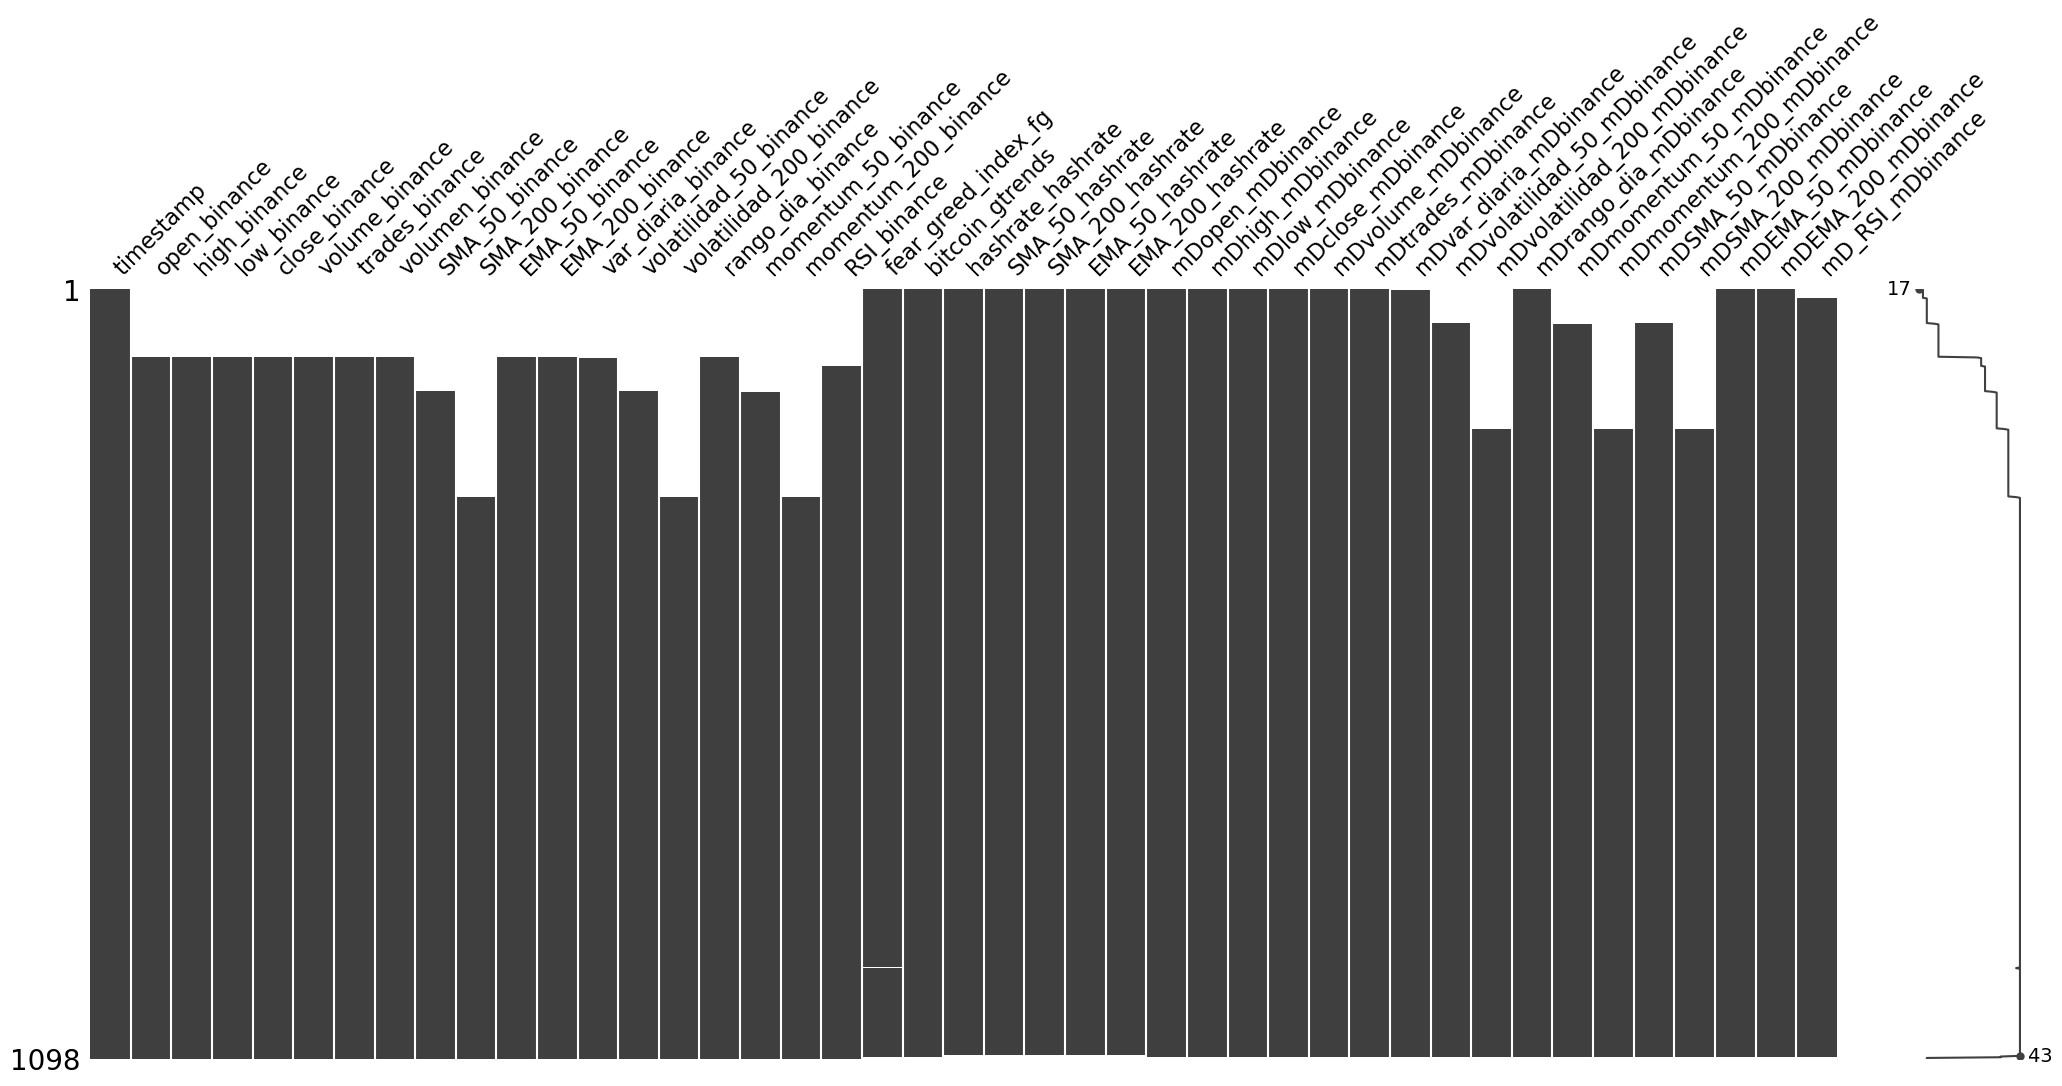

In [14]:
msno.matrix(df)

## 3. Correlaciones

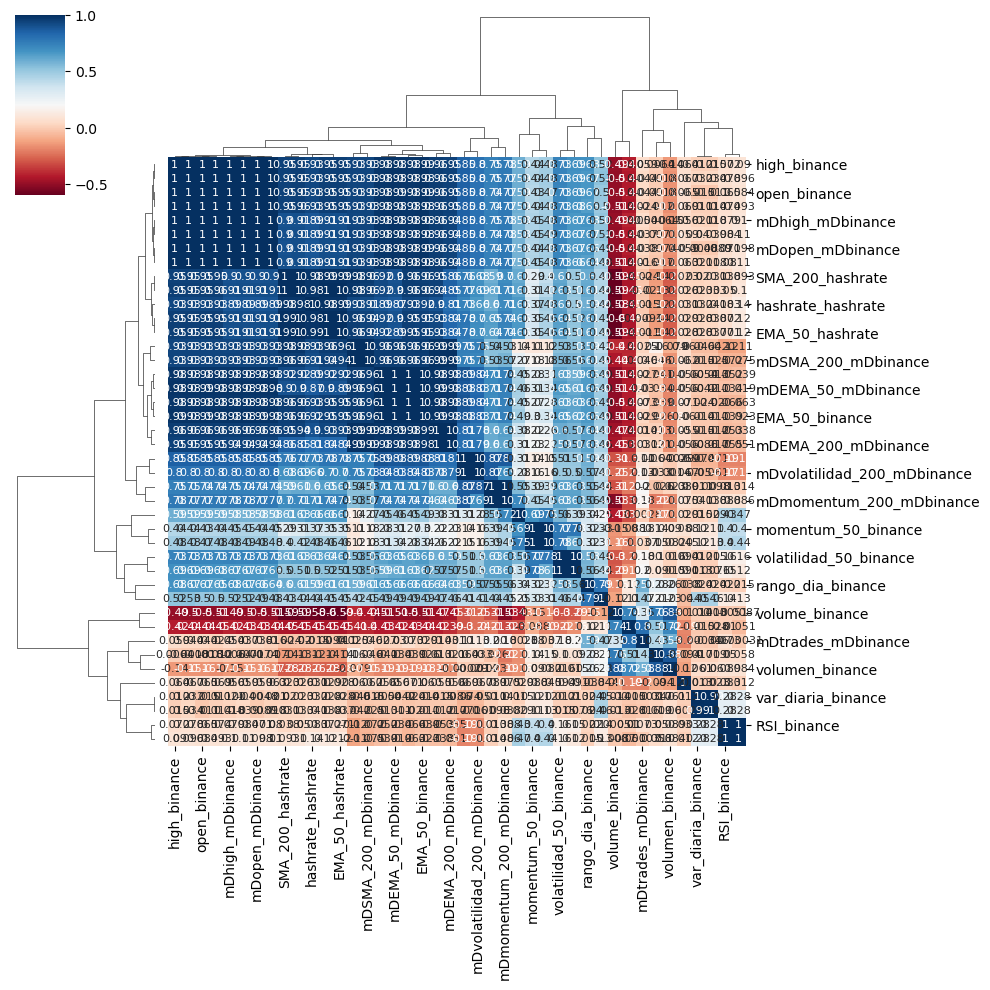

In [16]:
g = sns.clustermap(df.iloc[:, 1:].corr(), 
                   method = 'complete', 
                   cmap   = 'RdBu', 
                   annot  = True, 
                   annot_kws = {'size': 8})